# 13. Promotion – Retail Discount theo Label

Phân tích mối quan hệ giữa label và retail promotion trong cửa sổ 90 ngày trước cutoff.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.promotion_retail_discount_label import (
    load_promotion_retail_discount_report,
)
from propensity.eda.promotion_retail_discount_plots import (
    plot_retail_discount_boxplots,
    plot_retail_discount_ever_positive_rate,
)

## 1. Build leakage-safe retail-discount features

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"
transaction_path = project_root / "data" / "raw" / "Dunnhumby" / "transaction_data.csv"

report = load_promotion_retail_discount_report(
    label_path,
    transaction_path,
    observation_days=90,
)

## 2. Định nghĩa feature

| Feature | Định nghĩa |
|---|---|
| `ever_retail_discount_90d` | Có ít nhất một basket với tổng discount dương, sau khi đổi `RETAIL_DISC < 0` sang độ lớn dương |
| `retail_discount_basket_share_90d` | Số basket có retail discount / tổng số basket |
| `total_retail_discount_90d` | Tổng độ lớn retail discount |
| `retail_discount_to_sales_90d` | Tổng retail discount / tổng `SALES_VALUE` |

In [3]:
report.summary_by_label

,feature,label,n_observations,mean,q1,median,q3
0,ever_retail_discount_90d,0,94821,0.831873,1.000000,1.000000,1.000000
1,ever_retail_discount_90d,1,107423,0.986716,1.000000,1.000000,1.000000
2,retail_discount_basket_share_90d,0,94821,0.716918,0.600000,0.857143,1.000000
3,retail_discount_basket_share_90d,1,107423,0.843193,0.777778,0.875000,0.958333
4,total_retail_discount_90d,0,94821,38.360277,2.380000,18.530000,52.580000
5,total_retail_discount_90d,1,107423,109.773805,36.855000,81.990000,152.505000
6,retail_discount_to_sales_90d,0,94821,0.161125,0.067206,0.147454,0.223979
7,retail_discount_to_sales_90d,1,107423,0.181334,0.121984,0.166622,0.223957


## 3. Từng mua có retail discount và Positive rate

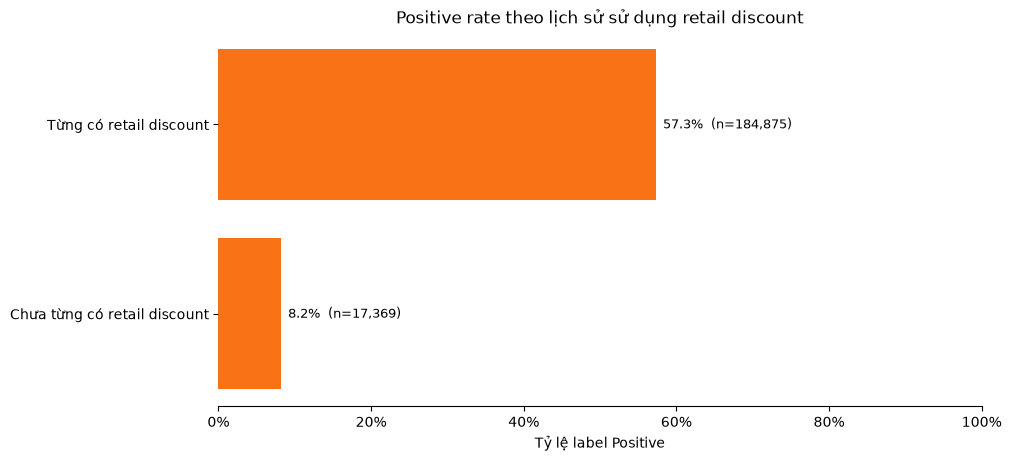

In [4]:
ever_discount_figure = plot_retail_discount_ever_positive_rate(
    report.feature_panel
)
plt.show()

## 4. Retail-discount intensity theo label

Box plot ẩn các điểm ngoại lai để tập trung vào khoảng P25–P75. Râu vẫn dùng quy tắc 1.5 × IQR.

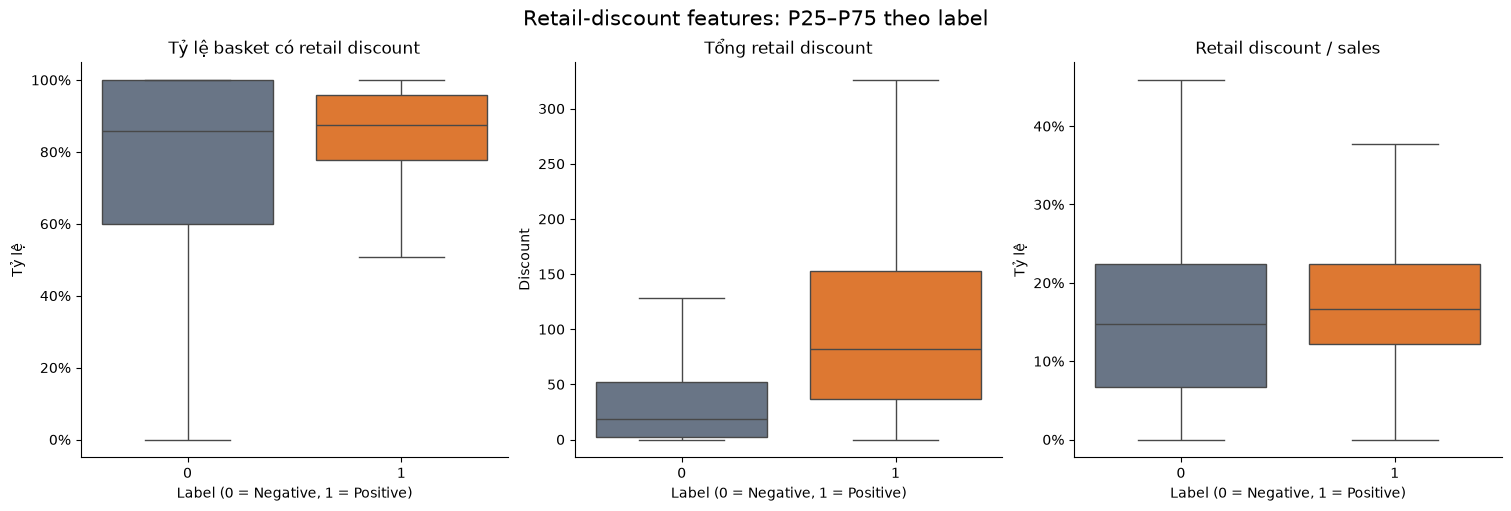

In [5]:
retail_discount_boxplots = plot_retail_discount_boxplots(
    report.feature_panel
)
plt.show()

## Lưu ý diễn giải

- Chỉ sử dụng giao dịch trong `[cutoff-90, cutoff-1]`; ngày cutoff không tham gia feature.
- `RETAIL_DISC` âm được hiểu là discount và đổi sang độ lớn dương; giá trị dương không được tính là discount.
- Household không có basket hợp lệ trong window nhận giá trị 0 cho các feature.
- `discount / sales` bằng 0 khi tổng sales không dương.
- Box plot ẩn marker ngoại lai để tập trung vào P25–P75; dữ liệu không bị loại khỏi bước tính feature.
- Các biểu đồ mô tả association, không chứng minh promotion gây ra label Positive.